RESULTADOS DE LA SIMULACIÓN (Tiempo hasta tocar suelo: t = 2.0526 s)
1. Error máx. RK45 vs Solución Analítica: 1.06e-10 m
2. Momento lineal horizontal p_x:         100.00 kg·m/s (Desv. típ.: 4.20e-09)
3. Momento angular intrínseco p_phi:      -840.00 kg·m^2/s (Desv. típ.: 0.00e+00)
4. Energía mecánica total E = T + U:      59597.50 J (Error rel.: 2.16e-12)
5. Tensión en la cuerda T = -lambda:      40.00 N (Analítica mu*l*omega0^2 = 40.00 N)



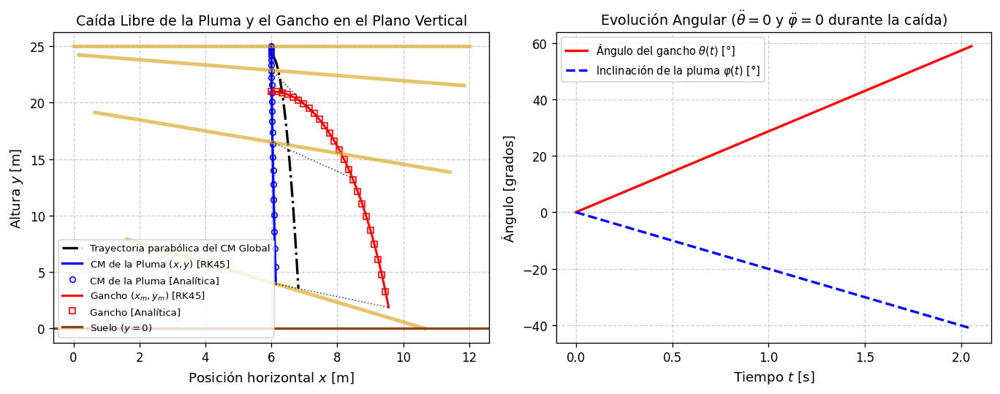

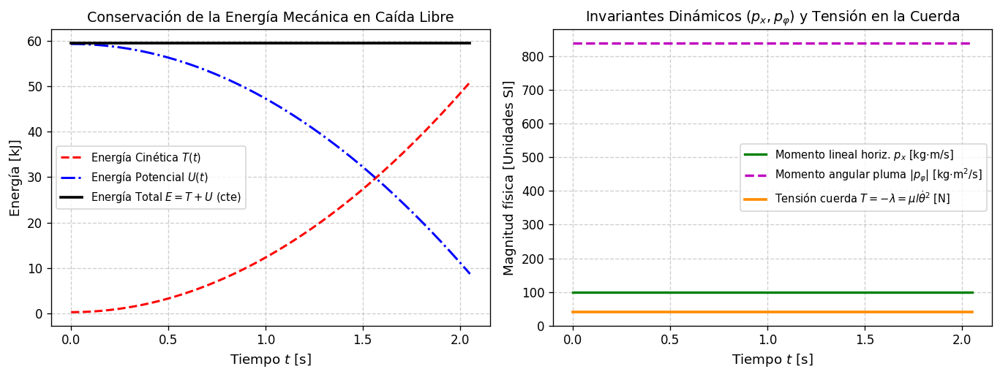

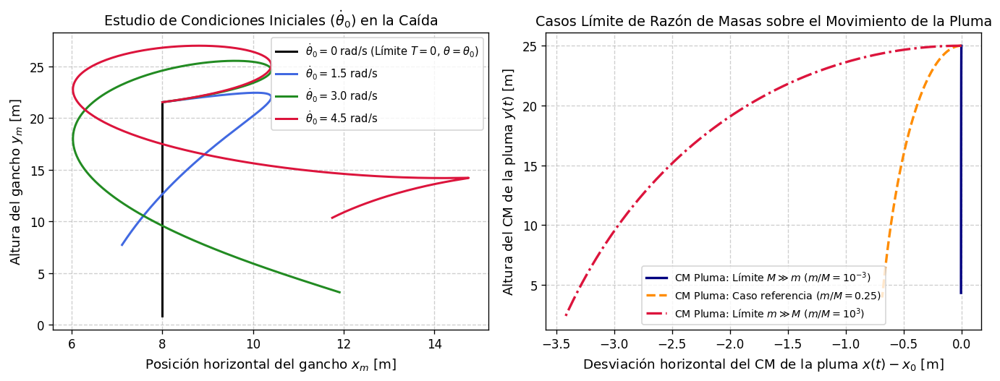

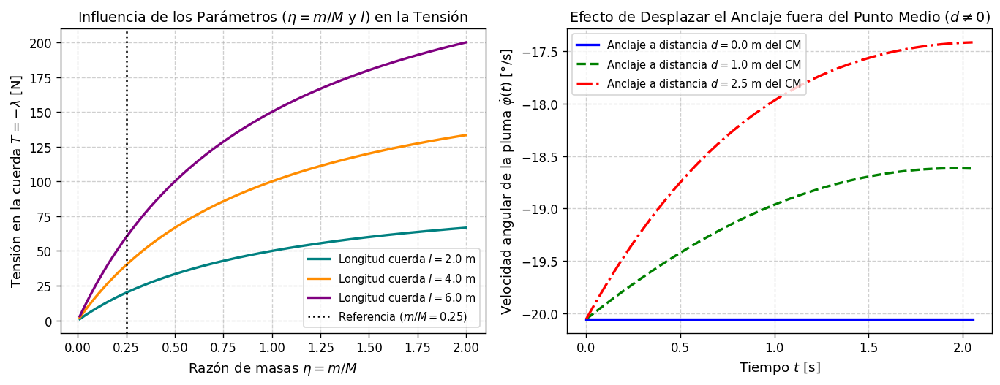

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Configuración gráfica
plt.rcParams.update({
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 11.5,
    'legend.fontsize': 8.8,
    'figure.dpi': 120
})

# Parámetros físicos del sistema
M = 200.0      # Masa de la pluma [kg]
m = 50.0       # Masa del gancho [kg]
L = 12.0       # Longitud de la pluma [m]
l = 4.0        # Longitud de la cuerda [m]
H = 25.0       # Altura inicial respecto al suelo [m]
g = 9.81       # Aceleración de la gravedad [m/s^2]

I_cm = (1.0 / 12.0) * M * (L ** 2)  # Momento de inercia de la pluma respecto a su CM [kg·m^2]
mu = (M * m) / (M + m)              # Masa reducida del sistema [kg]

# Estado inicial: [x, vx, y, vy, phi, phi_dot, theta, omega]
x0, y0 = L / 2.0, H
vx0, vy0 = 0.0, 0.0
phi0, phi_dot0 = 0.0, -0.35
theta0, omega0 = np.radians(0.0), 0.5

state0_ref = [x0, vx0, y0, vy0, phi0, phi_dot0, theta0, omega0]


def edos_pluma_gancho(t, state, M_p, m_g, L_p, l_c, g_val, d_exc=0.0):
    """
    Ecuaciones diferenciales de Euler-Lagrange para q = (x, y, phi, theta).
    El parámetro d_exc representa la distancia del punto de anclaje al CM de la pluma
    (d_exc = 0.0 cuando la cuerda cuelga exactamente de L/2).
    """
    x, vx, y, vy, phi, phi_dot, theta, omega = state
    I_p = (1.0 / 12.0) * M_p * (L_p ** 2)
    s_th, c_th = np.sin(theta), np.cos(theta)
    s_ph, c_ph = np.sin(phi), np.cos(phi)

    # Matriz de masas generalizada M(q) y vector de términos independientes (rhs)
    M_mat = np.array([
        [M_p + m_g, 0.0, -m_g * d_exc * s_ph, m_g * l_c * c_th],
        [0.0, M_p + m_g,  m_g * d_exc * c_ph, m_g * l_c * s_th],
        [-m_g * d_exc * s_ph, m_g * d_exc * c_ph, I_p + m_g * (d_exc**2),
         m_g * d_exc * l_c * np.sin(phi - theta)],
        [m_g * l_c * c_th, m_g * l_c * s_th,
         m_g * d_exc * l_c * np.sin(phi - theta), m_g * (l_c**2)]
    ])

    rhs = np.array([
        m_g * d_exc * (phi_dot**2) * c_ph + m_g * l_c * (omega**2) * s_th,
        -(M_p + m_g) * g_val + m_g * d_exc * (phi_dot**2) * s_ph - m_g * l_c * (omega**2) * c_th,
        -m_g * g_val * d_exc * c_ph + m_g * d_exc * l_c * (omega**2) * np.cos(phi - theta),
        -m_g * g_val * l_c * s_th - m_g * d_exc * l_c * (phi_dot**2) * np.cos(phi - theta)
    ])

    acc = np.linalg.solve(M_mat, rhs)
    return [vx, acc[0], vy, acc[1], phi_dot, acc[2], omega, acc[3]]


def solucion_analitica(t, state_ini, M_p, m_g, L_p, l_c, g_val):
    """Solución analítica exacta para el anclaje en el centro de masas (d_exc = 0)."""
    x_i, vx_i, y_i, vy_i, ph_i, ph_di, th_i, om_i = state_ini
    th_t = th_i + om_i * t
    ph_t = ph_i + ph_di * t

    # Evolución del Centro de Masas (CM) global del sistema
    vx_cm0 = vx_i + (m_g / (M_p + m_g)) * l_c * om_i * np.cos(th_i)
    vy_cm0 = vy_i + (m_g / (M_p + m_g)) * l_c * om_i * np.sin(th_i)
    x_cm = (x_i + (m_g / (M_p + m_g)) * l_c * np.sin(th_i)) + vx_cm0 * t
    y_cm = (y_i - (m_g / (M_p + m_g)) * l_c * np.cos(th_i)) + vy_cm0 * t - 0.5 * g_val * (t**2)

    # Coordenadas del CM de la pluma (x, y) y del gancho (xm, ym)
    x_t = x_cm - (m_g / (M_p + m_g)) * l_c * np.sin(th_t)
    y_t = y_cm + (m_g / (M_p + m_g)) * l_c * np.cos(th_t)
    xm_t = x_t + l_c * np.sin(th_t)
    ym_t = y_t - l_c * np.cos(th_t)
    return x_t, y_t, ph_t, th_t, xm_t, ym_t, x_cm, y_cm


# Evento para detener la integración cuando el gancho o los extremos de la pluma tocan el suelo (y = 0)
def evento_suelo(t, state, M_p, m_g, L_p, l_c, g_val, d_exc=0.0):
    x, vx, y, vy, phi, phi_dot, theta, omega = state
    ym = y - l_c * np.cos(theta)
    y_der = y + 0.5 * L_p * np.sin(phi)
    y_izq = y - 0.5 * L_p * np.sin(phi)
    return min(ym, y_der, y_izq)

evento_suelo.terminal = True
evento_suelo.direction = -1

# Integración numérica mediante Runge-Kutta de orden 4(5)
sol_detect = solve_ivp(edos_pluma_gancho, [0, 3.0], state0_ref,
                       args=(M, m, L, l, g, 0.0), events=evento_suelo,
                       method='RK45', rtol=1e-11, atol=1e-11)
t_impacto = sol_detect.t[-1]
t_eval = np.linspace(0, t_impacto, 300)

sol_ref = solve_ivp(edos_pluma_gancho, [0, t_impacto], state0_ref, t_eval=t_eval,
                    args=(M, m, L, l, g, 0.0), method='RK45', rtol=1e-11, atol=1e-11)

x_n, vx_n, y_n, vy_n, phi_n, phi_d_n, th_n, om_n = sol_ref.y
x_a, y_a, phi_a, th_a, xm_a, ym_a, xcm_a, ycm_a = solucion_analitica(t_eval, state0_ref, M, m, L, l, g)

xm_n = x_n + l * np.sin(th_n)
ym_n = y_n - l * np.cos(th_n)
vxm_n = vx_n + l * om_n * np.cos(th_n)
vym_n = vy_n + l * om_n * np.sin(th_n)

# Evaluación de magnitudes conservadas y tensión en la cuerda (T = -lambda)
px_n = (M + m) * vx_n + m * l * om_n * np.cos(th_n)
pphi_n = I_cm * phi_d_n
T_cin = 0.5 * M * (vx_n**2 + vy_n**2) + 0.5 * I_cm * (phi_d_n**2) + 0.5 * m * (vxm_n**2 + vym_n**2)
U_pot = M * g * y_n + m * g * ym_n
E_tot = T_cin + U_pot

tension_n = np.zeros_like(t_eval)
for i, ti in enumerate(t_eval):
    derivs = edos_pluma_gancho(ti, sol_ref.y[:, i], M, m, L, l, g, 0.0)
    x_dd, y_dd = derivs[1], derivs[3]
    tension_n[i] = m * (g * np.cos(th_n[i]) + l * (om_n[i]**2) - x_dd * np.sin(th_n[i]) + y_dd * np.cos(th_n[i]))

tension_exacta = mu * l * (omega0**2)

print("======================================================================")
print(f"RESULTADOS DE LA SIMULACIÓN (Tiempo hasta tocar suelo: t = {t_impacto:.4f} s)")
print("======================================================================")
print(f"1. Error máx. RK45 vs Solución Analítica: {np.max(np.abs(x_n - x_a)):.2e} m")
print(f"2. Momento lineal horizontal p_x:         {px_n[0]:.2f} kg·m/s (Desv. típ.: {np.std(px_n):.2e})")
print(f"3. Momento angular intrínseco p_phi:      {pphi_n[0]:.2f} kg·m^2/s (Desv. típ.: {np.std(pphi_n):.2e})")
print(f"4. Energía mecánica total E = T + U:      {E_tot[0]:.2f} J (Error rel.: {np.max(np.abs((E_tot-E_tot[0])/E_tot[0])):.2e})")
print(f"5. Tensión en la cuerda T = -lambda:      {tension_n[0]:.2f} N (Analítica mu*l*omega0^2 = {tension_exacta:.2f} N)")
print("======================================================================\n")

# Figura 1: Trayectorias en el plano vertical y evolución angular
fig1, axs1 = plt.subplots(1, 2, figsize=(11.5, 4.6))
axs1[0].plot(xcm_a, ycm_a, 'k-.', lw=2, label='Trayectoria parabólica del CM Global')
axs1[0].plot(x_n, y_n, 'b-', lw=2, label='CM de la Pluma $(x, y)$ [RK45]')
axs1[0].plot(x_a[::12], y_a[::12], 'bo', ms=4.5, fillstyle='none', label='CM de la Pluma [Analítica]')
axs1[0].plot(xm_n, ym_n, 'r-', lw=1.8, label='Gancho $(x_m, y_m)$ [RK45]')
axs1[0].plot(xm_a[::12], ym_a[::12], 'rs', ms=4.5, fillstyle='none', label='Gancho [Analítica]')

for idx_snap in [0, 95, 190, 299]:
    xc, yc, ph = x_n[idx_snap], y_n[idx_snap], phi_n[idx_snap]
    xi, yi = xc - 0.5*L*np.cos(ph), yc - 0.5*L*np.sin(ph)
    xd, yd = xc + 0.5*L*np.cos(ph), yc + 0.5*L*np.sin(ph)
    axs1[0].plot([xi, xd], [yi, yd], color='goldenrod', lw=3.0, alpha=0.65)
    axs1[0].plot([xc, xm_n[idx_snap]], [yc, ym_n[idx_snap]], 'k:', lw=1.0, alpha=0.7)

axs1[0].axhline(0, color='saddlebrown', lw=2, label='Suelo ($y=0$)')
axs1[0].set_xlabel('Posición horizontal $x$ [m]')
axs1[0].set_ylabel('Altura $y$ [m]')
axs1[0].set_title('Caída Libre de la Pluma y el Gancho en el Plano Vertical')
axs1[0].grid(True, linestyle='--', alpha=0.6)
axs1[0].legend(loc='lower left', fontsize=8)

axs1[1].plot(t_eval, np.degrees(th_n), 'r-', lw=2, label=r'Ángulo del gancho $\theta(t)$ [°]')
axs1[1].plot(t_eval, np.degrees(phi_n), 'b--', lw=2, label=r'Inclinación de la pluma $\varphi(t)$ [°]')
axs1[1].set_xlabel('Tiempo $t$ [s]')
axs1[1].set_ylabel('Ángulo [grados]')
axs1[1].set_title(r'Evolución Angular ($\ddot{\theta}=0$ y $\ddot{\varphi}=0$ durante la caída)')
axs1[1].grid(True, linestyle='--', alpha=0.6)
axs1[1].legend(loc='upper left')
plt.tight_layout()
plt.savefig('figura1_dinamica_caida.pdf')
plt.savefig('figura1_dinamica_caida.png', dpi=300)
plt.show()

# Figura 2: Conservación de la energía, invariantes dinámicos y tensión
fig2, axs2 = plt.subplots(1, 2, figsize=(11.5, 4.4))
axs2[0].plot(t_eval, T_cin / 1e3, 'r--', lw=1.8, label='Energía Cinética $T(t)$')
axs2[0].plot(t_eval, U_pot / 1e3, 'b-.', lw=1.8, label='Energía Potencial $U(t)$')
axs2[0].plot(t_eval, E_tot / 1e3, 'k-', lw=2.2, label='Energía Total $E = T + U$ (cte)')
axs2[0].set_xlabel('Tiempo $t$ [s]')
axs2[0].set_ylabel('Energía [kJ]')
axs2[0].set_title('Conservación de la Energía Mecánica en Caída Libre')
axs2[0].grid(True, linestyle='--', alpha=0.6)
axs2[0].legend()

axs2[1].plot(t_eval, px_n, 'g-', lw=2, label=r'Momento lineal horiz. $p_x$ [kg$\cdot$m/s]')
axs2[1].plot(t_eval, np.abs(pphi_n), 'm--', lw=2, label=r'Momento angular pluma $|p_{\varphi}|$ [kg$\cdot$m$^2$/s]')
axs2[1].plot(t_eval, tension_n, 'darkorange', lw=2.2, label=r'Tensión cuerda $T = -\lambda = \mu l \dot{\theta}^2$ [N]')
axs2[1].set_xlabel('Tiempo $t$ [s]')
axs2[1].set_ylabel('Magnitud física [Unidades SI]')
axs2[1].set_title(r'Invariantes Dinámicos ($p_x, p_{\varphi}$) y Tensión en la Cuerda')
axs2[1].grid(True, linestyle='--', alpha=0.6)
axs2[1].legend(loc='center right')
plt.tight_layout()
plt.savefig('figura2_constantes_tension.pdf')
plt.savefig('figura2_constantes_tension.png', dpi=300)
plt.show()

# Figura 3: influencia de las condiciones iniciales y casos límite de razón de masas
fig3, axs3 = plt.subplots(1, 2, figsize=(11.5, 4.5))
for om_val, col in zip([0.0, 1.5, 3.0, 4.5], ['black', 'royalblue', 'forestgreen', 'crimson']):
    st_ci = [x0, 0.0, y0, 0.0, 0.0, -0.45, np.radians(30.0), om_val]
    _, _, _, _, xm_c, ym_c, _, _ = solucion_analitica(t_eval, st_ci, M, m, L, l, g)
    etiqueta = rf"$\dot{{\theta}}_0 = 0$ rad/s (Límite $T=0$, $\theta=\theta_0$)" if om_val == 0 else rf"$\dot{{\theta}}_0 = {om_val:.1f}$ rad/s"
    axs3[0].plot(xm_c, ym_c, color=col, lw=1.8, label=etiqueta)

axs3[0].set_xlabel('Posición horizontal del gancho $x_m$ [m]')
axs3[0].set_ylabel('Altura del gancho $y_m$ [m]')
axs3[0].set_title(r'Estudio de Condiciones Iniciales ($\dot{\theta}_0$) en la Caída')
axs3[0].grid(True, linestyle='--', alpha=0.6)
axs3[0].legend()

casos_limite = [
    (1000.0, 1.0, r'Límite $M \gg m$ ($m/M = 10^{-3}$)', 'navy', '-'),
    (200.0, 50.0, r'Caso referencia ($m/M = 0.25$)', 'darkorange', '--'),
    (1.0, 1000.0, r'Límite $m \gg M$ ($m/M = 10^{3}$)', 'crimson', '-.')
]
for M_c, m_c, lbl, col, ls in casos_limite:
    vx0_cm = -(m_c / (M_c + m_c)) * l * omega0 * np.cos(theta0)
    st_lim = [x0, vx0_cm, y0, 0.0, 0.0, -0.45, theta0, omega0]
    x_c, y_c, _, _, _, _, _, _ = solucion_analitica(t_eval, st_lim, M_c, m_c, L, l, g)
    axs3[1].plot(x_c - x0, y_c, color=col, linestyle=ls, lw=2, label=f'CM Pluma: {lbl}')

axs3[1].set_xlabel(r'Desviación horizontal del CM de la pluma $x(t) - x_0$ [m]')
axs3[1].set_ylabel('Altura del CM de la pluma $y(t)$ [m]')
axs3[1].set_title('Casos Límite de Razón de Masas sobre el Movimiento de la Pluma')
axs3[1].grid(True, linestyle='--', alpha=0.6)
axs3[1].legend(fontsize=8.5)
plt.tight_layout()
plt.savefig('figura3_condiciones_iniciales_limites.pdf')
plt.savefig('figura3_condiciones_iniciales_limites.png', dpi=300)
plt.show()

# Figura 4: Dependencia paramétrica de la tensión y efecto de desplazar el punto de anclaje
fig4, axs4 = plt.subplots(1, 2, figsize=(11.5, 4.5))
eta_vec = np.linspace(0.01, 2.0, 200)
for l_cuerda, col in zip([2.0, 4.0, 6.0], ['teal', 'darkorange', 'purple']):
    T_curva = M * (eta_vec / (1.0 + eta_vec)) * l_cuerda * (omega0**2)
    axs4[0].plot(eta_vec, T_curva, color=col, lw=2, label=f'Longitud cuerda $l = {l_cuerda:.1f}$ m')

axs4[0].axvline(m / M, color='k', linestyle=':', label=f'Referencia ($m/M = {m/M:.2f}$)')
axs4[0].set_xlabel(r'Razón de masas $\eta = m / M$')
axs4[0].set_ylabel(r'Tensión en la cuerda $T = -\lambda$ [N]')
axs4[0].set_title(r'Influencia de los Parámetros ($\eta = m/M$ y $l$) en la Tensión')
axs4[0].grid(True, linestyle='--', alpha=0.6)
axs4[0].legend()

for d_val, col, ls in [(0.0, 'blue', '-'), (1.0, 'green', '--'), (2.5, 'red', '-.')]:
    sol_d = solve_ivp(edos_pluma_gancho, [0, t_impacto], state0_ref, t_eval=t_eval,
                      args=(M, m, L, l, g, d_val), method='RK45', rtol=1e-9, atol=1e-9)
    axs4[1].plot(t_eval, np.degrees(sol_d.y[5]), color=col, linestyle=ls, lw=2,
                 label=f'Anclaje a distancia $d = {d_val:.1f}$ m del CM')

axs4[1].set_xlabel('Tiempo $t$ [s]')
axs4[1].set_ylabel(r'Velocidad angular de la pluma $\dot{\varphi}(t)$ [°/s]')
axs4[1].set_title(r'Efecto de Desplazar el Anclaje fuera del Punto Medio ($d \neq 0$)')
axs4[1].grid(True, linestyle='--', alpha=0.6)
axs4[1].legend()
plt.tight_layout()
plt.savefig('figura4_estudio_parametrico.pdf')
plt.savefig('figura4_estudio_parametrico.png', dpi=300)
plt.show()


In [2]:
# =============================================================================
# BLOQUE 2: ANIMACIÓN INTERACTIVA HTML5 OPTIMIZADA PARA GOOGLE COLAB
# (Ejecutar después del Bloque 1; reproduce la Figura 1 del Examen en tiempo real)
# =============================================================================
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle, Polygon, Circle
from IPython.display import HTML
import numpy as np
import matplotlib.pyplot as plt

# Submuestreo a 75 fotogramas para renderizado instantáneo en Google Colab
n_frames = 75
idx_anim = np.linspace(0, len(t_eval) - 1, n_frames, dtype=int)
t_an = t_eval[idx_anim]
x_an, y_an = x_n[idx_anim], y_n[idx_anim]
phi_an, th_an = phi_n[idx_anim], th_n[idx_anim]
xm_an, ym_an = xm_n[idx_anim], ym_n[idx_anim]
xcm_an, ycm_an = xcm_a[idx_anim], ycm_a[idx_anim]
tens_an = tension_n[idx_anim]

fig_anim, (ax_sim, ax_dyn) = plt.subplots(
    1, 2, figsize=(11.5, 5.2), dpi=90, gridspec_kw={'width_ratios': [1.35, 1.0]}
)

# --- Panel Izquierdo: Escenario físico de la grúa (Torre fija + Pluma y Gancho cayendo) ---
ax_sim.set_xlim(-4.5, 17.5)
ax_sim.set_ylim(-1.8, H + 3.5)
ax_sim.set_aspect('equal')
ax_sim.grid(True, linestyle='--', alpha=0.45)
ax_sim.set_xlabel('Posición horizontal $x$ [m]')
ax_sim.set_ylabel('Altura $y$ [m]')
ax_sim.set_title('Desprendimiento y Caída Libre de la Pluma y el Gancho')

# Suelo y base
ax_sim.axhline(0, color='saddlebrown', lw=3, zorder=2)
ax_sim.fill_between([-4.5, 17.5], -1.8, 0, color='peru', alpha=0.28)

# Torre vertical de la grúa de altura H (idéntica a la Figura 1 del examen)
ax_sim.add_patch(Rectangle((-1.3, 0), 1.3, 3.2, facecolor='lightgray', edgecolor='dimgray', lw=1.5))
ax_sim.add_patch(Rectangle((-0.95, 3.2), 0.65, H - 3.8, facecolor='gold', edgecolor='darkgoldenrod', lw=1.2, hatch='xx'))
ax_sim.add_patch(Rectangle((-1.2, H - 0.8), 1.15, 1.2, facecolor='dodgerblue', edgecolor='navy', lw=1.5, zorder=3))
ax_sim.add_patch(Rectangle((-3.6, H - 0.35), 2.4, 0.5, facecolor='gold', edgecolor='darkgoldenrod', lw=1.2))
ax_sim.add_patch(Polygon([[-0.9, H + 0.4], [-0.62, H + 2.3], [-0.35, H + 0.4]], facecolor='orange', edgecolor='darkgoldenrod'))

# Silueta fantasma de la posición inicial horizontal (Panel izquierdo de la Fig. 1)
ax_sim.plot([0, L], [H, H], color='goldenrod', lw=5, alpha=0.22, label='Posición inicial ($t=0$)')
ax_sim.plot([L/2, L/2], [H, H - l], 'k--', lw=1, alpha=0.25)

# Objetos móviles: Pluma rígida (M, L), Anclaje fijo en L/2, Cuerda (l) y Gancho (m)
pluma_barra, = ax_sim.plot([], [], color='goldenrod', lw=7, solid_capstyle='butt', zorder=4, label='Pluma ($M, L$)')
pluma_borde, = ax_sim.plot([], [], color='black', lw=1.5, zorder=5)
anclaje_cm, = ax_sim.plot([], [], 'bo', ms=6.5, zorder=6, label='Anclaje fijo en CM ($L/2$)')
cuerda_lin, = ax_sim.plot([], [], 'k-', lw=2.0, zorder=4, label='Cuerda inextensible ($l$)')
gancho_masa = Circle((xm_an[0], ym_an[0]), 0.55, facecolor='crimson', edgecolor='black', lw=1.5, zorder=7, label='Gancho ($m$)')
ax_sim.add_patch(gancho_masa)

estela_pluma, = ax_sim.plot([], [], 'b--', lw=1.3, alpha=0.75, label='Trayectoria CM Pluma')
estela_gancho, = ax_sim.plot([], [], 'r-', lw=1.5, alpha=0.8, label='Trayectoria Gancho')
estela_cm_tot, = ax_sim.plot([], [], 'k-.', lw=1.4, alpha=0.7, label='Parábola CM Global')

caja_datos = ax_sim.text(0.28, 0.91, '', transform=ax_sim.transAxes, fontsize=9,
                         bbox=dict(boxstyle='round', facecolor='ivory', edgecolor='gray', alpha=0.92))
ax_sim.legend(loc='lower right', fontsize=7.8)

# --- Panel Derecho: Monitor en tiempo real de coordenadas generalizadas ---
ax_dyn.set_xlim(0, t_impacto)
ax_dyn.set_ylim(-65, 280)
ax_dyn.grid(True, linestyle='--', alpha=0.5)
ax_dyn.set_xlabel('Tiempo $t$ [s]')
ax_dyn.set_ylabel('Magnitud [° / m]')
ax_dyn.set_title(r'Evolución en Tiempo Real de las Coordenadas $(y, y_m, \bar{\varphi}, \theta)$')

ax_dyn.plot(t_eval, np.degrees(th_n), 'r-', alpha=0.25, lw=1.5)
ax_dyn.plot(t_eval, np.degrees(phi_n), 'b--', alpha=0.25, lw=1.5)
ax_dyn.plot(t_eval, y_n, 'g-.', alpha=0.25, lw=1.5)

curva_th, = ax_dyn.plot([], [], 'r-', lw=2, label=r'Ángulo gancho $\theta(t)$ [°]')
curva_ph, = ax_dyn.plot([], [], 'b--', lw=2, label=r'Ángulo pluma $\bar{\varphi}(t)$ [°]')
curva_y,  = ax_dyn.plot([], [], 'g-.', lw=2, label=r'Altura CM pluma $y(t)$ [m]')
cursor_t  = ax_dyn.axvline(0, color='gray', linestyle=':', lw=1.5)
ax_dyn.legend(loc='upper left', fontsize=8.5)

plt.tight_layout()

def animar(k):
    xc, yc, ph = x_an[k], y_an[k], phi_an[k]
    x_izq, y_izq = xc - 0.5 * L * np.cos(ph), yc - 0.5 * L * np.sin(ph)
    x_der, y_der = xc + 0.5 * L * np.cos(ph), yc + 0.5 * L * np.sin(ph)

    pluma_barra.set_data([x_izq, x_der], [y_izq, y_der])
    pluma_borde.set_data([x_izq, x_der], [y_izq, y_der])
    anclaje_cm.set_data([xc], [yc])
    cuerda_lin.set_data([xc, xm_an[k]], [yc, ym_an[k]])
    gancho_masa.center = (xm_an[k], ym_an[k])

    estela_pluma.set_data(x_an[:k+1], y_an[:k+1])
    estela_gancho.set_data(xm_an[:k+1], ym_an[:k+1])
    estela_cm_tot.set_data(xcm_an[:k+1], ycm_an[:k+1])

    curva_th.set_data(t_an[:k+1], np.degrees(th_an[:k+1]))
    curva_ph.set_data(t_an[:k+1], np.degrees(phi_an[:k+1]))
    curva_y.set_data(t_an[:k+1], y_an[:k+1])
    cursor_t.set_xdata([t_an[k], t_an[k]])

    caja_datos.set_text(
        f"t = {t_an[k]:.2f} s | y_pluma = {yc:.2f} m | y_gancho = {ym_an[k]:.2f} m\n"
        f"φ = {np.degrees(ph):.1f}° | θ = {np.degrees(th_an[k]):.1f}° | T = {tens_an[k]:.1f} N"
    )
    return (pluma_barra, pluma_borde, anclaje_cm, cuerda_lin, gancho_masa,
            estela_pluma, estela_gancho, estela_cm_tot, curva_th, curva_ph, curva_y, cursor_t, caja_datos)

ani = FuncAnimation(fig_anim, animar, frames=n_frames, interval=40, blit=True)
plt.close(fig_anim)
HTML(ani.to_jshtml())